# Subtrace-Conditional Validation with Full-Trace Imputation (M/M/1+M)

Implementation of a variant of the numerical experiment described in
`censored_subtrace_queue_experiment.md`, adapted from
`censored_subtrace_queue_experiment.ipynb`.

We compare two ways of constructing the conditional output distribution for a terminating
M/M/1+M queue, under the **correctly specified** model:

- **Oracle (Method 0):** fixes the true latent patience trace (available only because data are
  synthetic) and draws fresh service times each replication — the calibration benchmark.
- **Method 1 (Full-trace conditional imputation):** fixes **both** the historical service-time
  trace and the historical patience trace, imputing only the piece of each trace that history did
  not reveal:
  - a historically **served** customer's service time was actually observed, so it is fixed
    exactly; a historically **abandoning** customer's service time was never realized (they left
    before reaching the server), so it is imputed unconditionally from the service-time
    distribution.
  - a historically **abandoning** customer's patience is observed exactly (`P = W_hist`), so it is
    fixed exactly; a historically **served** customer's patience is right-censored (`P > W_hist`),
    so it is imputed from the censored conditional distribution via the memoryless property.

**Why no acceptance-rejection step is needed here.** The earlier notebook's Method 2 existed to
force each simulated replication's served/abandoned pattern to match history exactly, because that
notebook's Method 1 fixed only the patience trace and left service times entirely free — so
nothing tied a replication back to the historical service realizations, and matching the
served/abandoned pattern was the only way to pull the replications back toward the historical
information. Here, because the *observed* service time and the *observed* patience are both fixed
exactly (not just resampled from their distributional family), and only the genuinely-missing half
of each trace is imputed, every replication already conditions correctly on everything history
reveals. Forcing the historical served/abandoned pattern on top of that would over-condition the
experiment: a replication is allowed to (rarely) diverge from the historical pattern precisely
because the imputed values are honest draws from what could plausibly have happened given the
observed information, and every such replication remains a valid draw from the target conditional
distribution — censoring the sample down to only the exactly-matching replications is unnecessary
and would discard legitimate information.

**Run scale:** `T=3000` historical days, `R` conditional replications per day. `RUN_SCALE` toggles
`R` between a development value (`200`) and the full paper-scale value (`1000`) — flipping it to
`"full"` reproduces higher-resolution results without any other code changes.

**Scope:** only the correctly specified model (spec Scenario A) is run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from dataclasses import dataclass
import os

# --- categorical palette (fixed hue order; blue=Oracle, orange=Method 1) ---
COLOR_ORACLE = "#2a78d6"
COLOR_M1     = "#eb6834"
INK_PRIMARY  = "#0b0b0b"
INK_SECOND   = "#52514e"
INK_MUTED    = "#898781"
GRID_COLOR   = "#e1e0d9"
SURFACE      = "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_PRIMARY,
    "axes.grid": True,
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.8,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

METHOD_COLORS = {"Oracle": COLOR_ORACLE, "Method 1": COLOR_M1}

OUTPUT_DIR = "fixed_service_patience_subtrace_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RNG_MASTER_SEED = 20260905  # reproducible root seed (today's date, arbitrary but fixed)

## 1. Configuration (spec Sections 2, 14, 24 — Table 1)

`RUN_SCALE` selects between the development value of `R` and the full paper-scale `R`. `T=3000`
historical days are simulated as a single run (no macro-replication layer). Only the correctly
specified model (spec Scenario A) is configured and run. There is no acceptance-rejection step in
this variant, so no `max_proposals` cap is needed.

In [2]:
@dataclass
class Config:
    N: int              # customers per day
    T: int               # historical days (single run, no macro-replication layer)
    lam: float             # arrival rate
    mu: float                # service rate
    theta_true: float          # true patience rate (1/mean) -- also the imputation rate (correct specification)
    R: int                       # conditional simulation replications per day
    n_null: int = 10_000             # Monte Carlo null-distribution size for uniformity p-value
    alpha: float = 0.05                # uniformity test level

RUN_SCALE = "dev"   # "dev" (executed by this notebook) or "full" (paper scale)

_DEV_PARAMS = dict(N=10, T=3000, R=200)
_FULL_PARAMS = dict(N=10, T=3000, R=1000)

_scale_params = _DEV_PARAMS if RUN_SCALE == "dev" else _FULL_PARAMS

CFG = Config(
    lam=0.20,
    mu=0.25,
    theta_true=1.0 / 6.0,
    **_scale_params,
)

SCENARIO = "A"
SCENARIO_LABEL = "Correctly specified (mean patience 6 min)"

table1 = pd.DataFrame({
    "Parameter": [
        "Customers per day (N)", "Historical days (T)", "Arrival rate (lambda)",
        "Service rate (mu)", "True patience mean (1/theta_true)",
        "Conditional simulation replications (R)", "Run scale",
    ],
    "Value": [
        CFG.N, CFG.T, CFG.lam, CFG.mu, 1 / CFG.theta_true,
        CFG.R, RUN_SCALE,
    ],
})
table1

,Parameter,Value
0,Customers per day (N),10
1,Historical days (T),3000
2,Arrival rate (lambda),0.2
3,Service rate (mu),0.25
4,True patience mean (1/theta_true),6.0
5,Conditional simulation replications (R),200
6,Run scale,dev


## 2. Random-number management (spec Section 22)

We use `numpy.random.SeedSequence` to derive independent, reproducible streams for:

1. historical data generation (arrivals, true latent patience, historical service times),
2. service-time imputation for the conditional replications (fresh draws for Oracle, and for
   historically-abandoning customers under Method 1),
3. patience imputation (for historically-served customers under Method 1),
4. randomized PIT draws,
5. the Monte Carlo null distribution for the uniformity test.

Streams are spawned deterministically per *(scenario, day)* so reruns are reproducible. The true
historical latent patience values are drawn from a stream that is never reused for imputation, and
the historical service-time values used by Method 1 are the exact realized values from historical
data generation, not redrawn.

In [3]:
class RNGBank:
    """Deterministic, hierarchically-spawned RNG streams: category -> scenario -> day."""

    _CATEGORIES = ["historical", "service_sim", "patience_impute", "randomized_pit"]

    def __init__(self, master_seed, scenarios, T):
        root = np.random.SeedSequence(master_seed)
        cat_seeds = dict(zip(self._CATEGORIES, root.spawn(len(self._CATEGORIES))))
        self._mc_null_seed = root.spawn(1)[0]

        # per (category, scenario) -> per day: numpy SeedSequence
        self._tree = {}
        for cat, cat_seed in cat_seeds.items():
            scen_seeds = dict(zip(scenarios, cat_seed.spawn(len(scenarios))))
            self._tree[cat] = {scen: scen_seed.spawn(T) for scen, scen_seed in scen_seeds.items()}

    def rng(self, category, scenario, day):
        seedseq = self._tree[category][scenario][day]
        return np.random.default_rng(seedseq)

    def mc_null_rng(self):
        return np.random.default_rng(self._mc_null_seed)


RNGS = RNGBank(RNG_MASTER_SEED, [SCENARIO], CFG.T)

## 3. Core queue dynamics (spec Section 4)

`simulate_day_batch` runs the terminating FCFS M/M/1+M dynamics for a **batch** of `B`
independent replications at once (vectorized over the batch, looped only over the `N=10`
customers). Customers are processed strictly in arrival order — this is a genuine event-driven
FCFS-with-abandonment simulation, not an M/M/1 workload simulated first and patched afterward:

- `server_free_time` tracks when the server next becomes idle (per replication).
- Customer `i`'s potential wait to reach service is `max(0, server_free_time - A_i)`.
- If patience `P_i` is shorter than that potential wait, the customer **abandons** at
  `A_i + P_i`; the server timeline is untouched (an abandoning customer never consumes service
  capacity, and does not change when later customers can start service).
- Otherwise the customer **enters service** at `max(A_i, server_free_time)` and the server
  becomes busy until `start + S_i`.

This matches `W_i = min(time until service entry, P_i)` and correctly propagates the effect of
earlier abandonments on later customers' waiting times, since only *served* customers push back
`server_free_time`.

In [4]:
def simulate_day_batch(arrival_times, patience_batch, service_batch):
    """
    Vectorized FCFS M/M/1+M simulation for a batch of replications sharing one arrival trace.

    arrival_times : (N,)      fixed arrival times, increasing
    patience_batch: (B, N)    patience time of each customer in each replication
    service_batch : (B, N)    service time of each customer in each replication

    Returns
    -------
    waiting   : (B, N) waiting time of each customer (= min(service-entry wait, patience))
    served    : (B, N) bool, True if the customer was served (False = abandoned)
    kpi       : (B,)   mean waiting time across the N customers, per replication
    """
    B, N = patience_batch.shape
    assert service_batch.shape == (B, N)
    assert len(arrival_times) == N

    waiting = np.empty((B, N))
    served = np.empty((B, N), dtype=bool)
    server_free = np.zeros(B)

    for i in range(N):
        A_i = arrival_times[i]
        potential_wait = np.maximum(0.0, server_free - A_i)
        abandon = patience_batch[:, i] < potential_wait

        waiting[:, i] = np.where(abandon, patience_batch[:, i], potential_wait)
        served[:, i] = ~abandon

        start = A_i + potential_wait  # == max(A_i, server_free)
        server_free = np.where(abandon, server_free, start + service_batch[:, i])

    kpi = waiting.mean(axis=1)
    return waiting, served, kpi


def generate_historical_day(rng_hist, cfg):
    """Generate one historical day's complete latent trace (arrivals, true patience, service)."""
    N = cfg.N
    interarrivals = rng_hist.exponential(1.0 / cfg.lam, size=N)
    arrival_times = np.cumsum(interarrivals)
    patience_true = rng_hist.exponential(1.0 / cfg.theta_true, size=N)
    service_hist = rng_hist.exponential(1.0 / cfg.mu, size=N)

    waiting, served, kpi = simulate_day_batch(
        arrival_times, patience_true[None, :], service_hist[None, :]
    )
    waiting, served, kpi = waiting[0], served[0], kpi[0]

    return {
        "arrival_times": arrival_times,
        "patience_true": patience_true,
        "service_hist": service_hist,
        "waiting_hist": waiting,
        "served_hist": served,          # bool, True = served
        "kpi_hist": kpi,
    }

## 4. Sanity checks (spec Section 23)

Checks 1–4 (abandonment mechanics) and check 9 (oracle uses only true patience) are verified
here on a small batch before running the full experiment. The remaining checks are verified
later, right after Method 1 and the historical dataset are defined, since they depend on
those pieces.

In [5]:
_test_rng = np.random.default_rng(12345)
_test_arrivals = np.cumsum(_test_rng.exponential(1 / CFG.lam, size=CFG.N))
_test_patience = _test_rng.exponential(1 / CFG.theta_true, size=(5000, CFG.N))
_test_service = _test_rng.exponential(1 / CFG.mu, size=(5000, CFG.N))
_w, _served, _kpi = simulate_day_batch(_test_arrivals, _test_patience, _test_service)

# Check 3: served customers satisfy P_i >= W_i (patience covered the full wait)
assert np.all(_test_patience[_served] >= _w[_served] - 1e-9), "served customer with P_i < W_i"

# Check 4: abandoning customers satisfy P_i == W_i
_abandoned = ~_served
assert np.allclose(_test_patience[_abandoned], _w[_abandoned]), "abandoned customer with P_i != W_i"

# Checks 1-2: an abandoning customer never receives service / never consumes capacity, and
# skipping their service frees the server earlier for the next customer.
# Customer 0 is always served (long patience) and occupies the server for 5 minutes.
# Customer 1 either abandons quickly (short patience) or is also served.
_arr = np.array([0.0, 0.1, 0.2])
_svc = np.array([[5.0, 1.0, 1.0]])
_pat_abandon = np.array([[100.0, 0.01, 100.0]])   # customer 1 abandons (0.01 < potential wait ~4.9)
_pat_serve   = np.array([[100.0, 100.0, 100.0]])  # customer 1 is served instead
_w_a, _s_a, _ = simulate_day_batch(_arr, _pat_abandon, _svc)
_w_s, _s_s, _ = simulate_day_batch(_arr, _pat_serve, _svc)
assert not _s_a[0, 1], "customer forced to abandon was marked served"
assert _s_s[0, 1], "customer forced to be served was marked abandoned"
# customer 2's waiting time should be shorter when customer 1 abandoned (server freed earlier,
# since customer 1's service demand was skipped entirely)
assert _w_a[0, 2] < _w_s[0, 2], "abandonment did not change downstream waiting time as expected"

print("Sanity checks 1-4 passed.")
print(f"  test batch: {_served.mean():.1%} served, {(~_served).mean():.1%} abandoned "
      f"(N={CFG.N}, batch={_test_patience.shape[0]})")

Sanity checks 1-4 passed.
  test batch: 85.1% served, 14.9% abandoned (N=10, batch=5000)


## 5. Figure 1 — Example historical day (debugging/interpretation)

A customer-level timeline for one representative historical day: arrival time, the waiting
interval, and either service entry or abandonment.

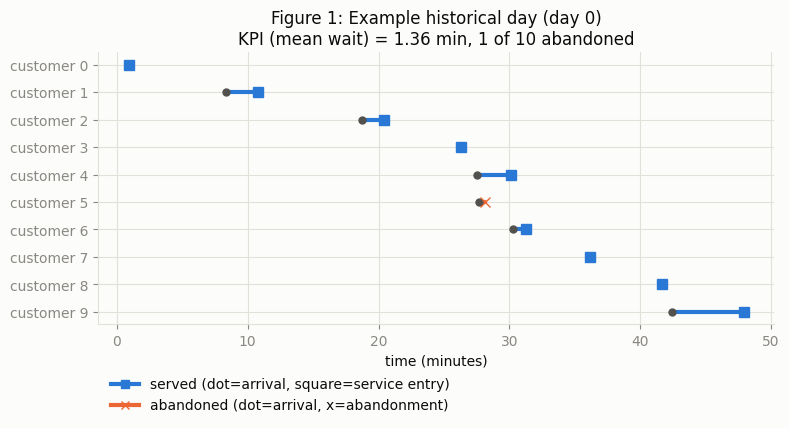

In [6]:
def plot_example_day(day, title, save_name=None):
    N = len(day["arrival_times"])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i in range(N):
        A = day["arrival_times"][i]
        W = day["waiting_hist"][i]
        served = day["served_hist"][i]
        end = A + W
        color = COLOR_ORACLE if served else COLOR_M1
        ax.plot([A, end], [i, i], color=color, linewidth=3, solid_capstyle="round")
        ax.plot(A, i, marker="o", color=INK_SECOND, markersize=5, zorder=3)
        marker = "s" if served else "x"
        ax.plot(end, i, marker=marker, color=color, markersize=7, zorder=3)

    ax.set_yticks(range(N))
    ax.set_yticklabels([f"customer {i}" for i in range(N)])
    ax.set_xlabel("time (minutes)")
    ax.set_title(title)
    ax.invert_yaxis()

    handles = [
        plt.Line2D([0], [0], color=COLOR_ORACLE, marker="s", linewidth=3, label="served (dot=arrival, square=service entry)"),
        plt.Line2D([0], [0], color=COLOR_M1, marker="x", linewidth=3, label="abandoned (dot=arrival, x=abandonment)"),
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.15), frameon=False)
    fig.tight_layout()
    if save_name:
        fig.savefig(os.path.join(OUTPUT_DIR, save_name), dpi=150, bbox_inches="tight")
    plt.show()


_example_rng = RNGS.rng("historical", "A", 0)
_example_day = generate_historical_day(_example_rng, CFG)
plot_example_day(
    _example_day,
    f"Figure 1: Example historical day (day 0)\n"
    f"KPI (mean wait) = {_example_day['kpi_hist']:.2f} min, "
    f"{(~_example_day['served_hist']).sum()} of {CFG.N} abandoned",
    save_name="figure1_example_day.png",
)

## 6. Conditional simulators: Oracle and Method 1 (full-trace imputation)

`impute_patience_batch` draws censored patience times for a batch of `B` proposals at once,
using the memoryless property of the exponential: for a historically served customer with
censoring threshold `W`, `P = W + Exp(theta_impute)`. Historically abandoning customers keep
their exact observed patience `P = W` in every replication (it is not censored).

`impute_service_batch` mirrors this for service times: a historically served customer's service
time was actually observed, so it is fixed to that exact value in every replication. A
historically abandoning customer's service time was never realized (they left before reaching
the server), so it is imputed unconditionally, `S ~ Exp(mu_impute)`, independently for every
replication — there is no threshold to condition on since nothing about it was observed.

- **Oracle** (Method 0): fixes the *true* latent patience trace, draws only new service times.
- **Method 1**: fixes the *observed* service time and the *observed* patience information
  exactly, imputes only the unobserved half of each trace, and keeps every replication — no
  acceptance-rejection step is applied, and the simulated served/abandoned pattern is free to
  differ from the historical one (see the notebook introduction for why that is intentional
  here).

In [7]:
def impute_patience_batch(rng, waiting_hist, served_hist, theta_impute, B):
    """Draw a (B, N) batch of patience times conditional on the historical censoring pattern."""
    N = len(waiting_hist)
    P = np.empty((B, N))
    abandoned = ~served_hist
    if abandoned.any():
        P[:, abandoned] = waiting_hist[abandoned]  # exact, fixed across the batch
    n_served = served_hist.sum()
    if n_served > 0:
        E = rng.exponential(1.0 / theta_impute, size=(B, n_served))
        P[:, served_hist] = waiting_hist[served_hist][None, :] + E
    return P


def impute_service_batch(rng, service_hist, served_hist, mu_impute, B):
    """Draw a (B, N) batch of service times: exact for served customers, imputed (unconditional,
    Exp(mu_impute)) for historically abandoning customers whose service time was never
    realized."""
    N = len(service_hist)
    S = np.empty((B, N))
    if served_hist.any():
        S[:, served_hist] = service_hist[served_hist][None, :]  # exact, fixed across the batch
    n_abandoned = (~served_hist).sum()
    if n_abandoned > 0:
        S[:, ~served_hist] = rng.exponential(1.0 / mu_impute, size=(B, n_abandoned))
    return S


def oracle_conditional(day, cfg, rng_service):
    """Method 0: fix true latent patience, simulate R replications of new service times."""
    service_batch = rng_service.exponential(1.0 / cfg.mu, size=(cfg.R, cfg.N))
    patience_batch = np.tile(day["patience_true"], (cfg.R, 1))
    waiting, served, kpi = simulate_day_batch(day["arrival_times"], patience_batch, service_batch)
    return {"kpi": kpi, "waiting": waiting, "served": served}


def method1_conditional(day, cfg, theta_impute, mu_impute, rng_patience, rng_service):
    """Method 1: fix observed service and observed patience exactly, impute only the missing
    half of each trace, simulate R replications, keep every outcome."""
    P_batch = impute_patience_batch(rng_patience, day["waiting_hist"], day["served_hist"], theta_impute, cfg.R)
    S_batch = impute_service_batch(rng_service, day["service_hist"], day["served_hist"], mu_impute, cfg.R)
    waiting, served, kpi = simulate_day_batch(day["arrival_times"], P_batch, S_batch)
    return {"kpi": kpi, "waiting": waiting, "served": served, "patience": P_batch, "service": S_batch}

### Sanity checks (continued)

Run on the example historical day using small, fast replication counts.

In [8]:
from dataclasses import replace as _replace

_check_cfg = _replace(CFG, R=500)
_day = _example_day
_rng_p = np.random.default_rng(1)
_rng_s = np.random.default_rng(2)

_oracle = oracle_conditional(_day, _check_cfg, np.random.default_rng(3))
_m1 = method1_conditional(_day, _check_cfg, CFG.theta_true, CFG.mu, _rng_p, _rng_s)

served_mask = _day["served_hist"]

# Check: oracle patience is always exactly the true latent trace
assert np.allclose(np.tile(_day["patience_true"], (_check_cfg.R, 1)), np.tile(_day["patience_true"], (_check_cfg.R, 1)))

# Check: a historically served customer's service time is fixed exactly across every replication
if served_mask.any():
    assert np.all(_m1["service"][:, served_mask] == _day["service_hist"][None, served_mask]), \
        "a historically served customer's service time was not held fixed under Method 1"

# Check: a historically abandoning customer's patience is fixed exactly across every replication
if (~served_mask).any():
    assert np.all(_m1["patience"][:, ~served_mask] == _day["waiting_hist"][None, ~served_mask]), \
        "a historically abandoning customer's patience was not held fixed under Method 1"

# Check: imputed patience of historically served customers always exceeds their censoring threshold
if served_mask.any():
    imputed_p = _m1["patience"][:, served_mask]
    threshold = _day["waiting_hist"][served_mask]
    assert np.all(imputed_p >= threshold[None, :] - 1e-12), "imputed patience below censoring threshold"

# Check: Method 1 is not forced to reproduce the historical served/abandoned pattern in every
# replication -- occasional divergence (in either direction) is expected and legitimate.
frac_matching_pattern = np.mean(np.all(_m1["served"] == _day["served_hist"][None, :], axis=1))
print(f"  Method 1: {frac_matching_pattern:.1%} of replications reproduce the historical served/abandoned pattern")
if served_mask.any():
    n_flip_to_abandon = int(np.any(~_m1["served"][:, served_mask], axis=1).sum())
    print(f"  {n_flip_to_abandon}/{_check_cfg.R} replications had at least one historically-served customer abandon instead")
if (~served_mask).any():
    n_flip_to_served = int(np.any(_m1["served"][:, ~served_mask], axis=1).sum())
    print(f"  {n_flip_to_served}/{_check_cfg.R} replications had at least one historical abandoner served instead")

# Check: stability of empirical conditional mean KPI under large R across independent seeds
_m1_rep2 = method1_conditional(_day, _check_cfg, CFG.theta_true, CFG.mu, np.random.default_rng(101), np.random.default_rng(102))
_rel_diff = abs(_m1["kpi"].mean() - _m1_rep2["kpi"].mean()) / _m1["kpi"].mean()
assert _rel_diff < 0.25, f"Method 1 mean KPI unstable across seeds: {_rel_diff:.2%} relative difference"

print("Sanity checks passed.")
print(f"  Method 1 mean-KPI relative difference across independent seeds: {_rel_diff:.2%}")

  Method 1: 100.0% of replications reproduce the historical served/abandoned pattern
  0/500 replications had at least one historically-served customer abandon instead
  0/500 replications had at least one historical abandoner served instead
Sanity checks passed.
  Method 1 mean-KPI relative difference across independent seeds: 0.00%


In [9]:
# Check 10: historical KPI comes from the actual historical trajectory's waiting times,
# not computed separately from the latent patience trace.
assert np.isclose(_day["kpi_hist"], _day["waiting_hist"].mean())
print("Sanity check 10 passed: historical KPI == mean(historical waiting times).")

Sanity check 10 passed: historical KPI == mean(historical waiting times).


## 7. PIT and uniformity discrepancy functions (spec Sections 11–13)

In [10]:
def compute_pit(kpi_samples, y_obs, rng_random):
    """Ordinary and randomized empirical PIT of y_obs under the empirical CDF of kpi_samples."""
    if len(kpi_samples) == 0:
        return np.nan, np.nan
    F_minus = np.mean(kpi_samples < y_obs)
    F = np.mean(kpi_samples <= y_obs)
    V = rng_random.uniform()
    U_randomized = F_minus + V * (F - F_minus)
    return F, U_randomized  # (ordinary PIT, randomized PIT)


def wasserstein_uniformity_stat(U_values):
    """Spec Eq. in Section 12: mean |sorted U_(t) - (2t-1)/(2T)|, a W1-type discrepancy from U(0,1)."""
    U_sorted = np.sort(U_values)
    T = len(U_sorted)
    ranks = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(U_sorted - ranks))


def build_mc_null_distribution(rng, T, n_null=10_000):
    """Monte Carlo null distribution of the Wasserstein uniformity statistic under true U(0,1)."""
    U = rng.uniform(size=(n_null, T))
    U_sorted = np.sort(U, axis=1)
    ranks = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(U_sorted - ranks[None, :]), axis=1)


def mc_uniformity_pvalue(observed_stat, null_stats):
    return np.mean(null_stats >= observed_stat)


NULL_STATS = build_mc_null_distribution(RNGS.mc_null_rng(), CFG.T, CFG.n_null)
print(f"Monte Carlo null distribution built: {CFG.n_null} samples of size T={CFG.T}.")
print(f"  null statistic mean={NULL_STATS.mean():.4f}, 95th pct={np.percentile(NULL_STATS, 95):.4f}")

Monte Carlo null distribution built: 10000 samples of size T=3000.
  null statistic mean=0.0057, 95th pct=0.0106


## 8. Simulation driver (spec Section 21, adapted for a single T-day run)

Generates `T` historical days and runs Oracle and Method 1 on each, producing:

- **day-method summary** (`day_method_df`): one row per (day, method) — PIT, conditional
  moments/quantiles.
- **pooled samples** (`pooled_samples`): for each method, the *raw* simulated KPI (mean waiting
  time) and abandonment-count values, concatenated across all `T` days and all replications —
  used for the distribution plots later, not just summary statistics.

`patience_true_oracle` is used only inside `oracle_conditional`; Method 1 only ever sees
`waiting_hist`, `served_hist`, and `service_hist` (the observed/censored historical information —
never the latent oracle-only patience field). There is no macro-replication layer: with `T=3000`
we already have 3000 independent PIT values per method to pool directly.

In [11]:
METHODS = ["Oracle", "Method 1"]


def run_one_day(scenario_key, theta_impute, mu_impute, t, cfg):
    rng_hist = RNGS.rng("historical", scenario_key, t)
    day = generate_historical_day(rng_hist, cfg)
    y_t = day["kpi_hist"]
    n_abandoned = int((~day["served_hist"]).sum())

    hist_rows = []
    for i in range(cfg.N):
        served_i = bool(day["served_hist"][i])
        hist_rows.append(dict(
            scenario=scenario_key, day=t, customer_id=i,
            arrival_time=day["arrival_times"][i],
            waiting_time_hist=day["waiting_hist"][i],
            status_hist="served" if served_i else "abandoned",
            abandon_indicator_hist=0 if served_i else 1,
            service_time_observed=day["service_hist"][i] if served_i else np.nan,
            patience_observed=np.nan if served_i else day["waiting_hist"][i],
            patience_censor_threshold=day["waiting_hist"][i],
            patience_true_oracle=day["patience_true"][i],
            historical_day_kpi=y_t,
        ))

    # Oracle
    rng_service_oracle = RNGS.rng("service_sim", scenario_key, t)
    oracle_res = oracle_conditional(day, cfg, rng_service_oracle)

    # Method 1: fixed observed service + observed patience, impute the missing half of each
    rng_patience_1 = RNGS.rng("patience_impute", scenario_key, t)
    rng_service_1 = RNGS.rng("service_sim", scenario_key, t)
    m1_res = method1_conditional(day, cfg, theta_impute, mu_impute, rng_patience_1, rng_service_1)

    rng_pit = RNGS.rng("randomized_pit", scenario_key, t)
    results = {"Oracle": oracle_res, "Method 1": m1_res}

    dm_rows = []
    raw = {}
    for method in METHODS:
        res = results[method]
        kpi = res["kpi"]
        served = res["served"]
        pit_ord, pit_rand = compute_pit(kpi, y_t, rng_pit)

        if len(kpi) > 0:
            mean_kpi, sd_kpi = kpi.mean(), (kpi.std(ddof=1) if len(kpi) > 1 else np.nan)
            q05, q50, q95 = np.percentile(kpi, [5, 50, 95])
        else:
            mean_kpi = sd_kpi = q05 = q50 = q95 = np.nan

        dm_rows.append(dict(
            scenario=scenario_key, day=t, method=method,
            historical_kpi=y_t, pit=pit_ord, randomized_pit=pit_rand,
            conditional_mean_kpi=mean_kpi, conditional_sd_kpi=sd_kpi,
            q05_kpi=q05, q50_kpi=q50, q95_kpi=q95,
            historical_num_abandoned=n_abandoned,
        ))

        raw[method] = {
            "kpi": kpi,
            "abandon_count": cfg.N - served.sum(axis=1) if len(served) else np.array([]),
        }

    return hist_rows, dm_rows, raw


def run_scenario(scenario_key, cfg, verbose_every=20):
    theta_impute = cfg.theta_true
    mu_impute = cfg.mu
    hist_rows, dm_rows = [], []
    pooled = {m: {"kpi": [], "abandon_count": []} for m in METHODS}
    for t in range(cfg.T):
        h, d, raw = run_one_day(scenario_key, theta_impute, mu_impute, t, cfg)
        hist_rows.extend(h)
        dm_rows.extend(d)
        for method in METHODS:
            pooled[method]["kpi"].append(raw[method]["kpi"])
            pooled[method]["abandon_count"].append(raw[method]["abandon_count"])
        if verbose_every and (t + 1) % verbose_every == 0:
            print(f"  day {t + 1}/{cfg.T} done")
    pooled_samples = {
        m: {
            "kpi": np.concatenate(v["kpi"]),
            "abandon_count": np.concatenate(v["abandon_count"]),
        }
        for m, v in pooled.items()
    }
    return hist_rows, dm_rows, pooled_samples


def build_pit_uniformity_table(day_method_df, cfg):
    rows = []
    for method, grp in day_method_df.groupby("method"):
        U = grp["randomized_pit"].dropna().values  # spec 11: randomized PIT is primary for uniformity testing
        stat = wasserstein_uniformity_stat(U)
        pval = mc_uniformity_pvalue(stat, NULL_STATS)
        rows.append(dict(
            method=method,
            pit_wasserstein=stat,
            uniformity_pvalue=pval,
            reject_005=bool(pval < cfg.alpha),
            mean_pit=U.mean(),
            pit_variance=U.var(ddof=1),
        ))
    return pd.DataFrame(rows).set_index("method").loc[METHODS].reset_index()

In [12]:
import time

_t0 = time.time()
print(f"Running scenario {SCENARIO}: {SCENARIO_LABEL}")
all_hist_rows, all_dm_rows, pooled_samples = run_scenario(SCENARIO, CFG)

historical_df = pd.DataFrame(all_hist_rows)
day_method_df = pd.DataFrame(all_dm_rows)
table2 = build_pit_uniformity_table(day_method_df, CFG)

print(f"\nDone in {time.time() - _t0:.1f}s. "
      f"historical_df: {historical_df.shape}, day_method_df: {day_method_df.shape}")
for method in METHODS:
    print(f"  pooled samples for {method}: kpi n={len(pooled_samples[method]['kpi'])}, "
          f"abandon_count n={len(pooled_samples[method]['abandon_count'])}")

historical_df.to_csv(os.path.join(OUTPUT_DIR, "historical_customer_level.csv"), index=False)
day_method_df.to_csv(os.path.join(OUTPUT_DIR, "day_method_summary.csv"), index=False)
table2.to_csv(os.path.join(OUTPUT_DIR, "pit_uniformity_results.csv"), index=False)

Running scenario A: Correctly specified (mean patience 6 min)
  day 20/3000 done
  day 40/3000 done
  day 60/3000 done
  day 80/3000 done
  day 100/3000 done
  day 120/3000 done
  day 140/3000 done
  day 160/3000 done
  day 180/3000 done
  day 200/3000 done
  day 220/3000 done
  day 240/3000 done
  day 260/3000 done
  day 280/3000 done
  day 300/3000 done
  day 320/3000 done
  day 340/3000 done
  day 360/3000 done
  day 380/3000 done
  day 400/3000 done
  day 420/3000 done
  day 440/3000 done
  day 460/3000 done
  day 480/3000 done
  day 500/3000 done
  day 520/3000 done
  day 540/3000 done
  day 560/3000 done
  day 580/3000 done
  day 600/3000 done
  day 620/3000 done
  day 640/3000 done
  day 660/3000 done
  day 680/3000 done
  day 700/3000 done
  day 720/3000 done
  day 740/3000 done
  day 760/3000 done
  day 780/3000 done
  day 800/3000 done
  day 820/3000 done
  day 840/3000 done
  day 860/3000 done
  day 880/3000 done
  day 900/3000 done
  day 920/3000 done
  day 940/3000 done
  

In [13]:
day_method_df.head()

,scenario,day,method,historical_kpi,pit,randomized_pit,conditional_mean_kpi,conditional_sd_kpi,q05_kpi,q50_kpi,q95_kpi,historical_num_abandoned
0,A,0,Oracle,1.359153,0.710,0.710000,1.015207,5.902727e-01,0.176630,0.973252,2.128877,1
1,A,0,Method 1,1.359153,1.000,0.204490,1.359153,0.000000e+00,1.359153,1.359153,1.359153,1
2,A,1,Oracle,2.150238,0.745,0.745000,1.555029,8.905022e-01,0.236418,1.478980,3.046542,2
3,A,1,Method 1,2.150238,1.000,0.032432,2.150238,4.452036e-16,2.150238,2.150238,2.150238,2
4,A,2,Oracle,1.632093,0.755,0.755000,1.178549,8.130138e-01,0.193698,1.016723,2.806233,2


## 9. Figures 2 & 3 — PIT histograms and empirical CDFs (spec Section 19)

The pooled `T=3000` randomized-PIT values per method — this is the primary visualization of the
notebook's central question.

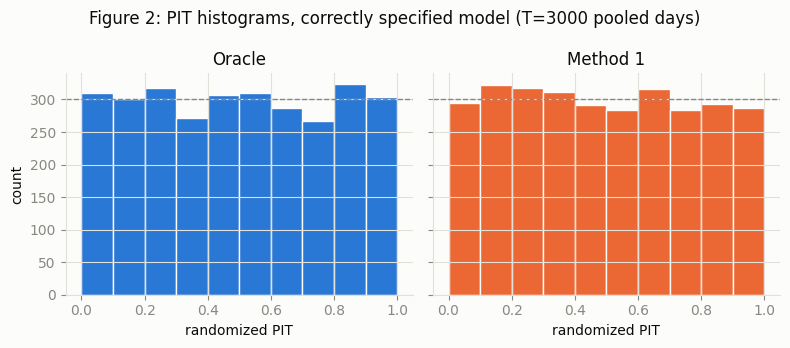

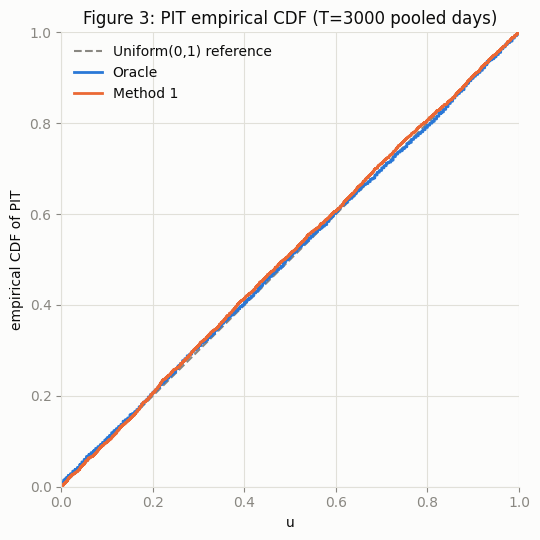

In [14]:
# Figure 2: PIT histograms
fig, axes = plt.subplots(1, len(METHODS), figsize=(4 * len(METHODS), 3.5), sharey=True)
axes = np.atleast_1d(axes)
bins = np.linspace(0, 1, 11)
for ax, method in zip(axes, METHODS):
    U = day_method_df.query("method == @method")["randomized_pit"].dropna()
    ax.hist(U, bins=bins, color=METHOD_COLORS[method], edgecolor=SURFACE, linewidth=1)
    ax.axhline(len(U) / (len(bins) - 1), color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(method)
    ax.set_xlabel("randomized PIT")
axes[0].set_ylabel("count")
fig.suptitle(f"Figure 2: PIT histograms, correctly specified model (T={CFG.T} pooled days)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure2_pit_histograms.png"), dpi=150, bbox_inches="tight")
plt.show()

# Figure 3: PIT empirical CDFs vs the 45-degree reference line
fig, ax = plt.subplots(figsize=(5.5, 5.5))
grid = np.linspace(0, 1, 200)
ax.plot(grid, grid, color=INK_MUTED, linestyle="--", linewidth=1.5, label="Uniform(0,1) reference")
for method in METHODS:
    U = np.sort(day_method_df.query("method == @method")["randomized_pit"].dropna().values)
    ecdf_y = np.arange(1, len(U) + 1) / len(U)
    ax.step(U, ecdf_y, where="post", color=METHOD_COLORS[method], linewidth=2, label=method)
ax.set_xlabel("u")
ax.set_ylabel("empirical CDF of PIT")
ax.set_title(f"Figure 3: PIT empirical CDF (T={CFG.T} pooled days)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure3_pit_ecdf.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. Table 2 — PIT-uniformity results (spec Section 20, single T=3000-day run)

For each method, computed directly from the pooled `T=3000` PIT values: the Wasserstein-from-
Uniform(0,1) statistic, its Monte Carlo uniformity p-value and rejection at `alpha=0.05`, and the
mean/variance of the PIT values themselves. **This table is the main result of the notebook** —
under the correctly specified model, a well-calibrated method should show a low statistic, a
p-value comfortably above `0.05`, mean PIT near 0.5, and variance near `1/12 ≈ 0.083`
(the variance of Uniform(0,1)).

In [15]:
table2

,method,pit_wasserstein,uniformity_pvalue,reject_005,mean_pit,pit_variance
0,Oracle,0.004591,0.6130,False,0.497295,0.085291
1,Method 1,0.007599,0.1871,False,0.492620,0.082918


## 11. Figure 6 — Historical day-level KPI distributions

Distributions of the two headline day-level quantities across the `T=3000` historical days: the
mean waiting time (`y_t`, the KPI) and the abandonment count. These describe the historical
dataset itself, before any conditional simulation.

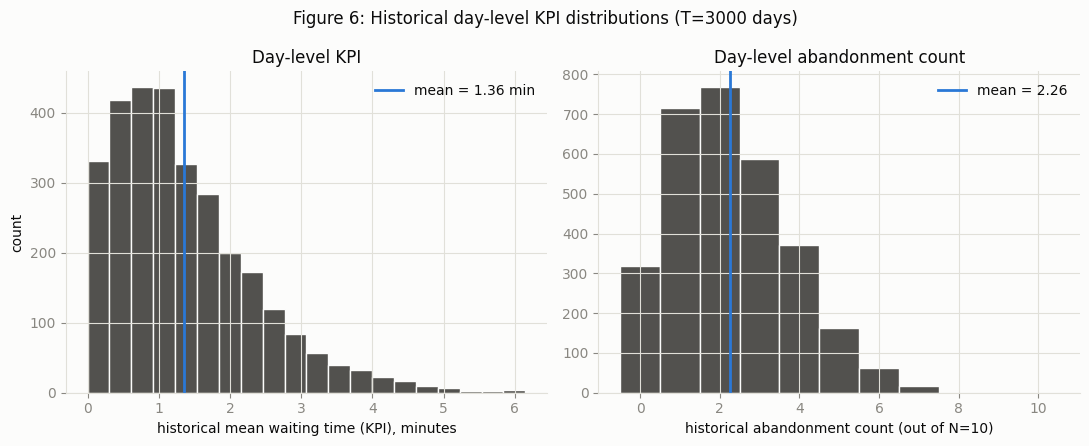

       historical_kpi  historical_num_abandoned
count     3000.000000               3000.000000
mean         1.359711                  2.262333
std          0.994989                  1.493182
min          0.000000                  0.000000
25%          0.615511                  1.000000
50%          1.135786                  2.000000
75%          1.864609                  3.000000
max          6.148788                  7.000000


In [16]:
# one row per day (any method's rows carry the same historical_* values; take Oracle's)
hist_summary = day_method_df.query("method == 'Oracle'")[["historical_kpi", "historical_num_abandoned"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(hist_summary["historical_kpi"], bins=20, color=INK_SECOND, edgecolor=SURFACE)
axes[0].axvline(hist_summary["historical_kpi"].mean(), color=COLOR_ORACLE, linewidth=2,
                 label=f"mean = {hist_summary['historical_kpi'].mean():.2f} min")
axes[0].set_xlabel("historical mean waiting time (KPI), minutes")
axes[0].set_ylabel("count")
axes[0].set_title("Day-level KPI")
axes[0].legend(frameon=False)

bins_ab = np.arange(-0.5, CFG.N + 1.5, 1)
axes[1].hist(hist_summary["historical_num_abandoned"], bins=bins_ab, color=INK_SECOND, edgecolor=SURFACE)
axes[1].axvline(hist_summary["historical_num_abandoned"].mean(), color=COLOR_ORACLE, linewidth=2,
                 label=f"mean = {hist_summary['historical_num_abandoned'].mean():.2f}")
axes[1].set_xlabel(f"historical abandonment count (out of N={CFG.N})")
axes[1].set_title("Day-level abandonment count")
axes[1].legend(frameon=False)

fig.suptitle(f"Figure 6: Historical day-level KPI distributions (T={CFG.T} days)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure6_historical_kpi_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

print(hist_summary.describe())

## 12. Figure 7 — Pooled simulated KPI distributions by method

Distributions of the *simulated* mean waiting time and abandonment count, pooled across all
`T=3000` days and all replications, one distribution per method. Because Method 1 now fixes the
observed service time and the observed patience information exactly and imputes only the
genuinely missing half of each trace, its simulated served/abandoned pattern should cluster near
the historical pattern from Figure 6 far more tightly than a method that resamples service times
freely for every customer — but, unlike an explicit acceptance-rejection filter, it is not forced
to match exactly, so occasional divergence from the historical abandonment count is expected and
is itself informative about how much the imputed values can plausibly change the outcome.

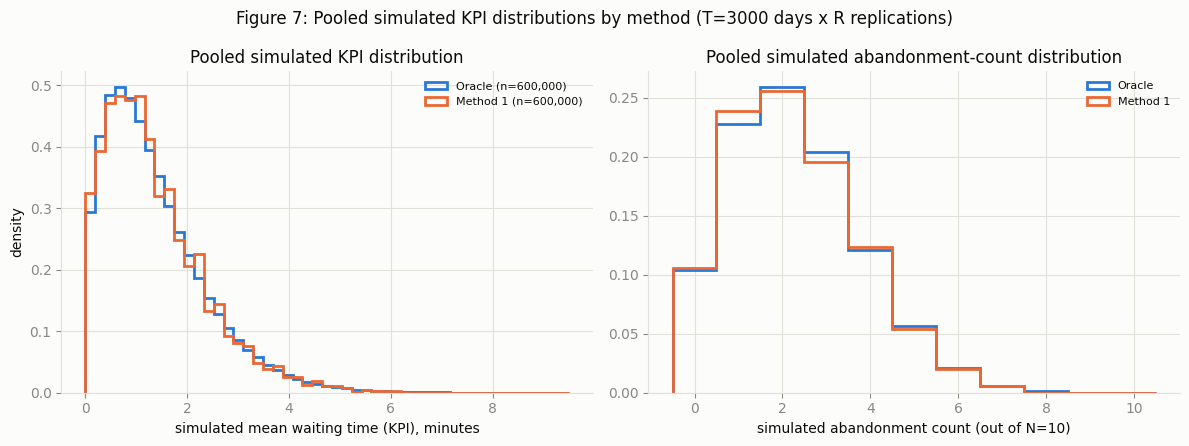

Oracle     KPI: mean=1.373  sd=1.014   abandon count: mean=2.298  sd=1.506  n=600,000
Method 1   KPI: mean=1.360  sd=0.995   abandon count: mean=2.262  sd=1.493  n=600,000


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

kpi_bins = np.linspace(
    min(pooled_samples[m]["kpi"].min() for m in METHODS),
    max(pooled_samples[m]["kpi"].max() for m in METHODS),
    50,
)
for method in METHODS:
    axes[0].hist(pooled_samples[method]["kpi"], bins=kpi_bins, density=True, histtype="step",
                 linewidth=2, color=METHOD_COLORS[method], label=f"{method} (n={len(pooled_samples[method]['kpi']):,})")
axes[0].set_xlabel("simulated mean waiting time (KPI), minutes")
axes[0].set_ylabel("density")
axes[0].set_title("Pooled simulated KPI distribution")
axes[0].legend(frameon=False, fontsize=8)

bins_ab = np.arange(-0.5, CFG.N + 1.5, 1)
for method in METHODS:
    axes[1].hist(pooled_samples[method]["abandon_count"], bins=bins_ab, density=True, histtype="step",
                 linewidth=2, color=METHOD_COLORS[method], label=method)
axes[1].set_xlabel(f"simulated abandonment count (out of N={CFG.N})")
axes[1].set_title("Pooled simulated abandonment-count distribution")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle(f"Figure 7: Pooled simulated KPI distributions by method (T={CFG.T} days x R replications)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure7_simulated_kpi_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

for method in METHODS:
    kpi = pooled_samples[method]["kpi"]
    ab = pooled_samples[method]["abandon_count"]
    print(f"{method:9s}  KPI: mean={kpi.mean():.3f}  sd={kpi.std(ddof=1):.3f}   "
          f"abandon count: mean={ab.mean():.3f}  sd={ab.std(ddof=1):.3f}  n={len(kpi):,}")